After running [assignwcs](https://jwst-pipeline.readthedocs.io/en/latest/jwst/assign_wcs/main.html) and [extract2d](https://jwst-pipeline.readthedocs.io/en/latest/jwst/extract_2d/main.html#overview) of the jwst pipeline.

In [1]:
%matplotlib ipympl

In [2]:
from astropy.io import fits
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate

In [3]:
# assignwcs = fits.open("../../../../../data/assignwcssteps/jw05022001001_04102_00001-seg001_nrs1_1_extract2dstep.fits")
# assignwcs.info()

In [4]:
extract2d = fits.open("../../../../../data/extract2dsteps/jw05022001001_04102_00001-seg001_nrs1_1_extract2dstep.fits")
wvl_array = extract2d["WAVELENGTH"].data
extract2d.info()

Filename: ../../../../../data/extract2dsteps/jw05022001001_04102_00001-seg001_nrs1_1_extract2dstep.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     239   ()      
  1  SCI           1 ImageHDU        77   (431, 21, 5160)   float32   
  2  ERR           1 ImageHDU        11   (431, 21, 5160)   float32   
  3  DQ            1 ImageHDU        12   (431, 21, 5160)   int32 (rescales to uint32)   
  4  WAVELENGTH    1 ImageHDU         9   (431, 21)   float32   
  5  VAR_POISSON    1 ImageHDU        10   (431, 21, 5160)   float32   
  6  VAR_RNOISE    1 ImageHDU        10   (431, 21, 5160)   float32   
  7  INT_TIMES     1 BinTableHDU     24   5160R x 7C   [J, D, D, D, D, D, D]   
  8  ASDF          1 BinTableHDU     11   1R x 1C   [162006B]   


In [5]:
xpos = pickle.load(open("../pickled_objects/x_positions_1.pickle","rb"))
xpos_mean = xpos.mean(axis=0)

In [6]:
less ../../extraction_input.txt

########################
### Paths to input files

### NOTE: all .fits files must be oriented such that the dispersion direction is along the vertical axis. Run rotate_spectra.py first to do this! ###

# This is a .txt file containing the names (on separate rows) of all science frames. This can be created on the command line through  $ ls *appropriate files* > science_list. For most users this will be defined as $ ls **/*1_gainscalestep.fits > science_list. However it can be a single reference frame from which the script will load all subsequent files in cwd OR outputted by sort_ACAM_files.py/sort_EFOSC_files.py
science_list = science_list

# The path to the master bias .fits file. If this is not given, a frame padded with zeroes is used. This should not be defined if you're using JWST data and have performed the super bias step in stage0.
master_bias = 

# The path to the master flat .fits file. If this is not given, a frame padded with ones is used.
master_flat = 

# The path to the 

In [7]:
row_min = 20
row_max = 280
oversampling_factor = 10

xpos /= oversampling_factor
xpos_mean /= oversampling_factor

In [8]:
np.nanmin(wvl_array),np.nanmax(wvl_array)

(np.float32(0.54956406), np.float32(5.3775654))

In [9]:
wvl_array.shape

(21, 431)

/tmp/ipykernel_3234624/3859655410.py:5: RuntimeWarning: Mean of empty slice
  plt.plot(np.nanmean(s1,axis=0))


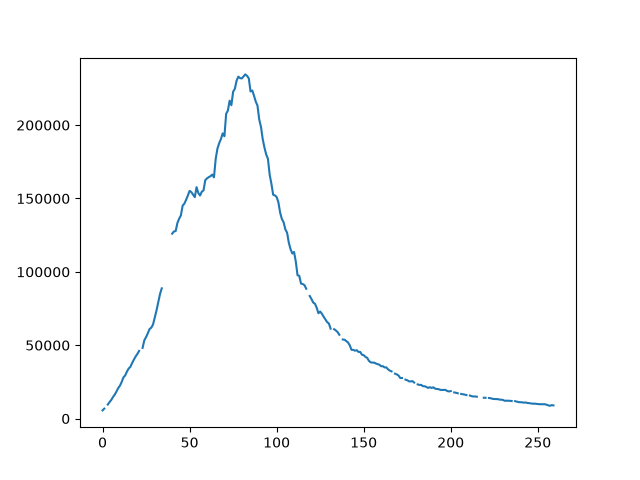

In [14]:
# s1 = pickle.load(open("../pickled_objects/star1_flux_resampled.pickle","rb"))
s1 = pickle.load(open("../pickled_objects/star1_flux.pickle","rb"))

plt.figure()
plt.plot(np.nanmean(s1,axis=0))
plt.show()

OK, this time I'm going to rotate the wavelength array so that it has same orientation as xpos

In [15]:
rotated_wvl_array = np.flip(wvl_array.T,axis=1)

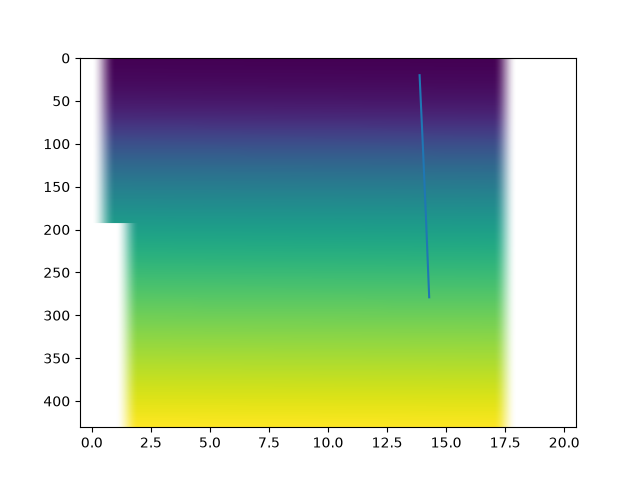

In [16]:
plt.figure()
plt.imshow(rotated_wvl_array,aspect="auto")
plt.plot(xpos_mean,np.arange(row_min,row_max))
plt.show()

In [17]:
wvl_solution = []

for i,row in enumerate(np.arange(row_min,row_max)):
    x = np.round(xpos_mean[i]).astype(int)
    w = rotated_wvl_array[row][x]
    wvl_solution.append(w)
    
wvl_solution = np.array(wvl_solution)

<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3234624/4249217549.py:3: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Wavelength ($\mu$m)")


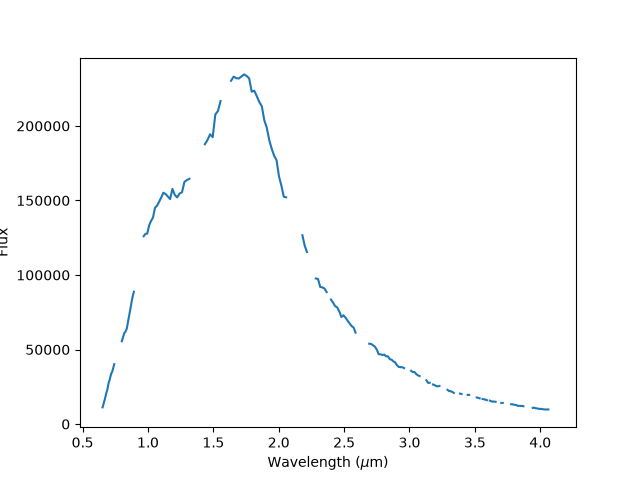

In [18]:
plt.figure()
plt.plot(wvl_solution,s1.mean(axis=0))
plt.xlabel("Wavelength ($\mu$m)")
plt.ylabel("Flux")
plt.show()

In [19]:
pickle.dump(wvl_solution,open("../pickled_objects/wvl_solution.pickle","wb"))